# RQ1 Step 1: Velocity-persistence baseline

This notebook evaluates a velocity-persistence baseline on the fixed Region A forecast cases. It assumes that the eastward and northward velocity observed at the forecast origin remains constant for the next 72 hours. No parameters are learned from the test set.


## 1. Method

For each case, the forecast-origin velocity is held fixed and integrated forward for 72 one-hour steps. Predicted and observed positions are compared with Haversine separation error. The method is intentionally simple and provides a physically interpretable benchmark for all learned models.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display

ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'processed').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not find data/processed; open the notebook from the project directory or a notebook subdirectory.')

PROCESSED = PROJECT_ROOT / 'data' / 'processed'
OUTPUT_DIR = PROJECT_ROOT / 'output' / 'rq1' / 'en'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EARTH_RADIUS_M = 6_371_000.0
HORIZON_HOURS = 72
plt.rcParams['font.sans-serif'] = ['PingFang SC', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('Project directory: ', PROJECT_ROOT.resolve())
print('Output directory: ', OUTPUT_DIR.resolve())

Matplotlib is building the font cache; this may take a moment.


Project directory:  /Users/roger/Documents/data3001-project-main
Output directory:  /Users/roger/Documents/data3001-project-main/output/rq1/en


## 2. Read the fixed forecast cases and observations

`forecast_origins.parquet` fixes the case origin, partition and forecast window. `region_A_observations.parquet` supplies the observed future positions. This notebook does not resample cases or modify the training/calibration/test split.


In [2]:
origins = pd.read_parquet(PROCESSED / 'forecast_origins.parquet')
observations = pd.read_parquet(
    PROCESSED / 'region_A_observations.parquet',
    columns=['ID', 'segment_id', 'segment_step', 'time', 'latitude', 'longitude'],
)

dataset_summary = pd.DataFrame({
    'Dataset': ['Training', 'Calibration', 'Test', 'Total'],
    'Forecast cases': [
        origins['partition'].eq('training').sum(),
        origins['partition'].eq('calibration').sum(),
        origins['partition'].eq('test').sum(),
        len(origins),
    ],
})
display(dataset_summary)
assert len(origins) == 5117
assert origins[['origin_ve', 'origin_vn']].notna().all().all()

,Dataset,Forecast cases
0,Training,3591
1,Calibration,769
2,Test,757
3,Total,5117


## 3. Expand every case to 72 lead times

Each forecast origin is expanded to 72 rows, one for each future hour. The merge keys retain drifter and continuous-segment identity so that observations from different tracks cannot be mixed.


In [3]:
case_columns = [
    'forecast_case_id', 'ID', 'segment_id', 'partition',
    'target_start_step', 'origin_time', 'origin_latitude', 'origin_longitude',
    'origin_ve', 'origin_vn',
]
expanded = origins[case_columns].loc[origins.index.repeat(HORIZON_HOURS)].reset_index(drop=True)
expanded['lead_time_hours'] = np.tile(np.arange(1, HORIZON_HOURS + 1), len(origins))
expanded['segment_step'] = expanded['target_start_step'] + expanded['lead_time_hours'] - 1

truth = observations.rename(columns={
    'time': 'valid_time',
    'latitude': 'true_latitude',
    'longitude': 'true_longitude',
})
evaluation = expanded.merge(
    truth,
    on=['ID', 'segment_id', 'segment_step'],
    how='left',
    validate='many_to_one',
)

expected_rows = len(origins) * HORIZON_HOURS
checks = pd.Series({
    'Total rows equal 5117 x 72': len(evaluation) == expected_rows,
    'All observed positions matched successfully': evaluation[['true_latitude', 'true_longitude']].notna().all().all(),
    'Every case has exactly 72 lead times': evaluation.groupby('forecast_case_id').size().eq(72).all(),
}, name='Passed')
display(checks.to_frame())
assert checks.all(), 'Failed to construct observed future positions.'

,Passed
Total rows equal 5117 x 72,True
All observed positions matched successfully,True
Every case has exactly 72 lead times,True


## 4. Integrate constant velocity to obtain positions

Velocity is measured in metres per second. Each one-hour displacement therefore multiplies velocity by 3,600 seconds, with spherical latitude/longitude corrections used to update position.


In [4]:
lat0_rad = np.deg2rad(evaluation['origin_latitude'].to_numpy())
lon0_rad = np.deg2rad(evaluation['origin_longitude'].to_numpy())
lead = evaluation['lead_time_hours'].to_numpy()
ve = evaluation['origin_ve'].to_numpy()
vn = evaluation['origin_vn'].to_numpy()

# Latitude at the end of forecast hour h.
pred_lat_rad = lat0_rad + vn * 3600.0 * lead / EARTH_RADIUS_M

# Convert eastward displacement using latitude at the start of each hour, then accumulate within case.
lat_before_step = lat0_rad + vn * 3600.0 * (lead - 1) / EARTH_RADIUS_M
cos_lat = np.cos(lat_before_step)
if np.any(np.abs(cos_lat) < 1e-8):
    raise ValueError('A position is too close to a pole for stable longitude integration.')
evaluation['delta_lon_rad_step'] = ve * 3600.0 / (EARTH_RADIUS_M * cos_lat)
cumulative_delta_lon = evaluation.groupby('forecast_case_id')['delta_lon_rad_step'].cumsum().to_numpy()
pred_lon_rad = lon0_rad + cumulative_delta_lon

evaluation['pred_latitude'] = np.rad2deg(pred_lat_rad)
evaluation['pred_longitude'] = (np.rad2deg(pred_lon_rad) + 180.0) % 360.0 - 180.0
evaluation[['forecast_case_id', 'lead_time_hours', 'pred_latitude', 'pred_longitude']].head()

,forecast_case_id,lead_time_hours,pred_latitude,pred_longitude
0,1,1,26.843432,125.218100
1,1,2,26.842225,125.229359
2,1,3,26.841017,125.240618
3,1,4,26.839810,125.251877
4,1,5,26.838602,125.263136


## 5. Calculate Haversine separation error

For every case and lead time, the Haversine formula calculates the great-circle distance between the predicted and observed position in kilometres. The same function is used for every RQ1 model.


In [5]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.deg2rad(np.asarray(lat1, dtype=float))
    lon1 = np.deg2rad(np.asarray(lon1, dtype=float))
    lat2 = np.deg2rad(np.asarray(lat2, dtype=float))
    lon2 = np.deg2rad(np.asarray(lon2, dtype=float))
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * (EARTH_RADIUS_M / 1000.0) * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

evaluation['separation_error_km'] = haversine_km(
    evaluation['pred_latitude'], evaluation['pred_longitude'],
    evaluation['true_latitude'], evaluation['true_longitude'],
)
assert np.isfinite(evaluation['separation_error_km']).all()
evaluation['separation_error_km'].describe(percentiles=[0.5, 0.9, 0.95]).to_frame('km')

,km
count,368424.000000
mean,35.988273
std,37.825700
min,0.000149
50%,24.439636
90%,83.618568
95%,109.993251
max,494.686940


## 6. Held-out test results by lead time

Only the 757 test cases are summarised here. The median describes a typical error, the interquartile range shows the middle 50% of cases, and RMSE is more sensitive to large errors.


In [6]:
test_eval = evaluation[evaluation['partition'].eq('test')].copy()
lead_metrics = (
    test_eval.groupby('lead_time_hours')['separation_error_km']
    .agg(
        n='size',
        median_error_km='median',
        mean_error_km='mean',
        q25_error_km=lambda x: x.quantile(0.25),
        q75_error_km=lambda x: x.quantile(0.75),
        rmse_km=lambda x: np.sqrt(np.mean(np.square(x))),
    )
    .reset_index()
)
assert test_eval['forecast_case_id'].nunique() == 757
assert lead_metrics['n'].eq(757).all()
display(lead_metrics[lead_metrics['lead_time_hours'].isin([1, 6, 12, 24, 48, 72])].round(2))

,lead_time_hours,n,median_error_km,mean_error_km,q25_error_km,q75_error_km,rmse_km
0,1,757,0.13,0.26,0.07,0.29,0.47
5,6,757,2.77,3.47,1.50,4.59,4.52
11,12,757,7.48,8.90,4.28,11.55,11.10
23,24,757,16.47,19.48,9.47,25.54,24.07
47,48,757,36.54,44.96,22.89,59.58,55.17
71,72,757,61.35,73.82,37.43,97.40,90.10


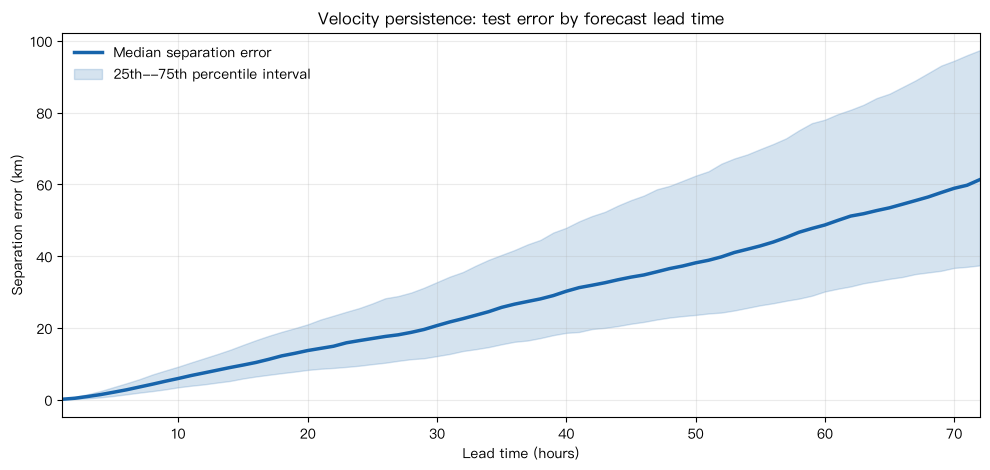

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.8))
x = lead_metrics['lead_time_hours'].to_numpy()
median = lead_metrics['median_error_km'].to_numpy()
q25 = lead_metrics['q25_error_km'].to_numpy()
q75 = lead_metrics['q75_error_km'].to_numpy()
ax.plot(x, median, color='#1764ab', linewidth=2.5, label='Median separation error')
ax.fill_between(x, q25, q75, color='#1764ab', alpha=0.18, label='25th--75th percentile interval')
ax.set(xlabel='Lead time (hours)', ylabel='Separation error (km)',
       title='Velocity persistence: test error by forecast lead time')
ax.set_xlim(1, 72)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'velocity_persistence_error_curve.png', dpi=200, bbox_inches='tight')
plt.show()

## 7. Case-level integrated trajectory error and summary

Integrated trajectory error (ITE) is the trapezoidal area under each case's 0--72 hour separation-error curve. It measures error accumulated over the complete trajectory rather than only at the final point.


In [8]:
def case_metrics(group):
    ordered = group.sort_values('lead_time_hours')
    errors = ordered['separation_error_km'].to_numpy()
    hours = ordered['lead_time_hours'].to_numpy()
    ite = np.trapezoid(np.r_[0.0, errors], x=np.r_[0, hours])
    return pd.Series({
        'integrated_trajectory_error_km_h': ite,
        'final_72h_error_km': errors[-1],
        'mean_trajectory_error_km': errors.mean(),
    })

test_case_metrics = test_eval.groupby('forecast_case_id', sort=False).apply(
    case_metrics, include_groups=False
).reset_index()

def metric_at(hour, column):
    return float(lead_metrics.loc[lead_metrics['lead_time_hours'].eq(hour), column].iloc[0])

summary = pd.DataFrame({
    'Metric': [
        'Test cases', '24h median error (km)', '48h median error (km)',
        '72h median error (km)', '72h RMSE (km)', 'Median ITE (km·h)',
    ],
    'Value': [
        test_eval['forecast_case_id'].nunique(),
        metric_at(24, 'median_error_km'), metric_at(48, 'median_error_km'),
        metric_at(72, 'median_error_km'), metric_at(72, 'rmse_km'),
        test_case_metrics['integrated_trajectory_error_km_h'].median(),
    ],
})
display(summary.round(2))

,Metric,Value
0,Test cases,757.00
1,24h median error (km),16.47
2,48h median error (km),36.54
3,72h median error (km),61.35
4,72h RMSE (km),90.10
5,Median ITE (km·h),1962.45


## 8. Representative trajectory

The displayed case has a 72-hour endpoint error closest to the test-set median, avoiding a selectively best or worst example.


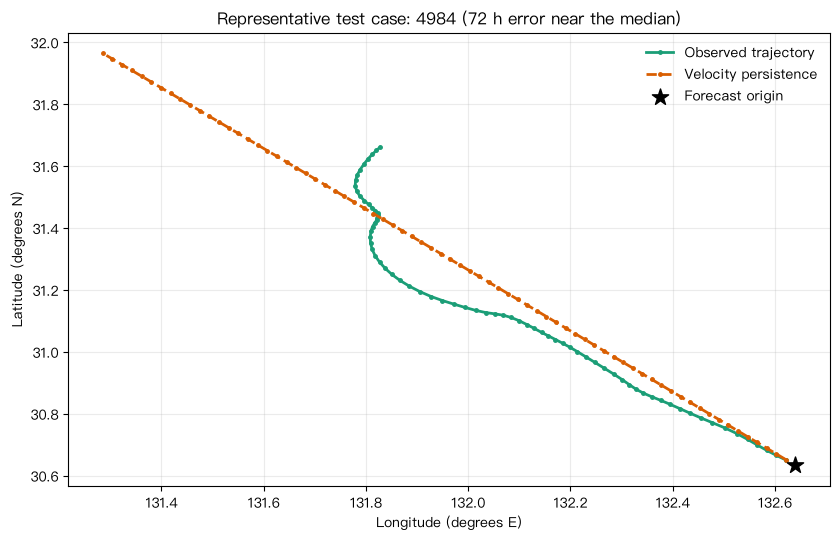

In [9]:
median_final = test_case_metrics['final_72h_error_km'].median()
example_id = test_case_metrics.loc[
    (test_case_metrics['final_72h_error_km'] - median_final).abs().idxmin(),
    'forecast_case_id',
]
example = test_eval[test_eval['forecast_case_id'].eq(example_id)].sort_values('lead_time_hours')

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(example['true_longitude'], example['true_latitude'], '-o', markersize=2.5,
        linewidth=2, color='#1b9e77', label='Observed trajectory')
ax.plot(example['pred_longitude'], example['pred_latitude'], '--o', markersize=2.5,
        linewidth=2, color='#d95f02', label='Velocity persistence')
ax.scatter(example['origin_longitude'].iloc[0], example['origin_latitude'].iloc[0],
           marker='*', s=150, color='black', label='Forecast origin', zorder=5)
ax.set(xlabel='Longitude (degrees E)', ylabel='Latitude (degrees N)',
       title=f'Representative test case: {int(example_id)} (72 h error near the median)')
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'velocity_persistence_example_trajectory.png', dpi=200, bbox_inches='tight')
plt.show()

## 9. Save reproducible results

Save lead-time metrics, case-level metrics, the compact summary and poster-ready figures.


In [10]:
lead_metrics.to_csv(OUTPUT_DIR / 'velocity_persistence_lead_metrics.csv', index=False)
test_case_metrics.to_csv(OUTPUT_DIR / 'velocity_persistence_test_case_metrics.csv', index=False)
summary.to_csv(OUTPUT_DIR / 'velocity_persistence_summary.csv', index=False)

saved_files = sorted(p.name for p in OUTPUT_DIR.glob('velocity_persistence_*'))
print('Saved:')
for name in saved_files:
    print(' -', name)

Saved:
 - velocity_persistence_error_curve.png
 - velocity_persistence_example_trajectory.png
 - velocity_persistence_lead_metrics.csv
 - velocity_persistence_summary.csv
 - velocity_persistence_test_case_metrics.csv
